# Aula 24 — Amostragem, representatividade e pesquisa de opinião

Estamos em período eleitoral, então toda semana aparece uma manchete do tipo **"Fulano tem 41%, Beltrano tem 38%"**. Tem gente que acredita cegamente, tem gente que diz que "pesquisa não vale nada". Nenhum dos dois lados está olhando para o que importa: **como** aquele número foi produzido.

Hoje a gente vai responder, com a mão na massa, perguntas como:

- Por que ouvir 1.200 pessoas pode dizer algo sobre 150 milhões de eleitores?
- Por que uma enquete com 50 mil votos no X/Instagram vale **menos** que uma pesquisa com 1.200 entrevistas?
- O que é **margem de erro**, **intervalo de confiança** e **nível de confiança de 95%**?
- Quando dois candidatos estão "tecnicamente empatados"?
- O que uma pessoa de comunicação precisa checar antes de repetir um número de pesquisa?

Começamos pequeno: aqui na nossa própria sala. Depois vamos escalar para um eleitorado inteiro, tudo em simulação (sem precisar de dado externo).

## 1. Começando do começo: arroz em cima ou embaixo do feijão?

**Missão ao vivo (3 minutos):** cada pessoa responde, **sem conversar com ninguém**, a pergunta *"Na hora de servir o prato, você coloca o arroz em cima ou embaixo do feijão?"*. Alguém anota o grupo (menina ou menino) e a resposta de cada estudante.

A sala inteira é a nossa **população**. Se todo mundo respondeu, temos um **censo**: a resposta verdadeira para "qual a proporção da sala que põe o arroz em cima?".

A tabela abaixo é um **exemplo fictício**, só para o notebook rodar. **Depois da votação real, troque as listas `grupo_por_fileira` e `voto_por_fileira` pelas da nossa turma**: cada string é uma fileira, uma letra por pessoa (`F`/`M` e `C`/`B`), na ordem dos lugares. Fileiras podem ter tamanhos diferentes (10, 5, 7...).

**OBS:** o número da fileira sai automaticamente do tamanho de cada string. Se uma fileira tiver 10 letras em `grupo` e 10 em `voto`, são 10 pessoas naquela fileira.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# F = menina, M = menino | C = arroz em cima, B = arroz embaixo
# cada string da lista = uma fileira (pode ter tamanhos diferentes)
grupo_por_fileira = ["FFFFFMFFFF", "FMFFM", "FFMF", "MM"]
voto_por_fileira  = ["CCCCCBCCCB", "CBCBB", "CCBB", "BB"]

if len(grupo_por_fileira) != len(voto_por_fileira):
    raise ValueError("grupo_por_fileira e voto_por_fileira precisam ter o mesmo número de fileiras")
if any(len(g) != len(v) for g, v in zip(grupo_por_fileira, voto_por_fileira)):
    raise ValueError("em cada fileira, grupo e voto precisam ter o mesmo número de letras")

grupo, voto, fileira = [], [], []
for n_fileira, (g, v) in enumerate(zip(grupo_por_fileira, voto_por_fileira), start=1):
    grupo.extend(g)
    voto.extend(v)
    fileira.extend([n_fileira] * len(g))

sala = pd.DataFrame({
    "aluno": [f"Aluno {i + 1:02d}" for i in range(len(grupo))],
    "fileira": fileira,
    "grupo": grupo,
    "voto": ["em cima" if v == "C" else "embaixo" for v in voto],
})
print(sala.shape)
print("pessoas por fileira:", sala["fileira"].value_counts().sort_index().to_dict())
sala

(21, 4)
pessoas por fileira: {1: 10, 2: 5, 3: 4, 4: 2}


,aluno,fileira,grupo,voto
0,Aluno 01,1,F,em cima
1,Aluno 02,1,F,em cima
2,Aluno 03,1,F,em cima
3,Aluno 04,1,F,em cima
4,Aluno 05,1,F,em cima
5,Aluno 06,1,M,embaixo
6,Aluno 07,1,F,em cima
7,Aluno 08,1,F,em cima
8,Aluno 09,1,F,em cima
9,Aluno 10,1,F,embaixo


**Ponto de conferência:** a tabela tem uma linha por pessoa e as colunas `fileira`, `grupo` e `voto`? Rode a próxima célula para ver o **censo**, ou seja, a verdade da sala. Na linguagem de estatística, essa proporção é o **parâmetro** da população.

In [2]:
sala["cima"] = (sala["voto"] == "em cima")   # True/False: facilita calcular proporção

censo = sala["cima"].mean()
print(f"Censo: {censo:.0%} da sala põe o arroz em cima")
print()
print(sala.groupby("grupo")["cima"].agg(["mean", "count"]).rename(columns={"mean": "prop_em_cima", "count": "pessoas"}))

Censo: 57% da sala põe o arroz em cima

       prop_em_cima  pessoas
grupo                       
F               0.8       15
M               0.0        6


### E se a gente não pudesse perguntar para todo mundo?

Imagine que só dava para ouvir **6 pessoas**. Quem escolher? Vamos comparar três jeitos reais de "fazer pesquisa":

1. **A fileira da frente** (quem está mais perto, o jeito mais cômodo);
2. **Quem levantou a mão primeiro** (voluntários);
3. **Um sorteio**: cada pessoa da sala tem a mesma chance de ser escolhida.

Na célula abaixo, a fileira da frente e o sorteio já estão prontos. **Sua missão:** troque o `random_state` do sorteio (1, 2, 3...) e veja o resultado mudar. O que isso diz sobre uma amostra pequena?

In [11]:
frente = sala[sala["fileira"] == 1]
sorteio = sala.sample(6, random_state=4)    # troque o 1 por outros números

tabela = pd.DataFrame({
    "método": ["Censo (verdade)", "Fileira da frente", "Sorteio de 6"],
    "pessoas": [len(sala), len(frente), len(sorteio)],
    "arroz em cima": [censo, frente["cima"].mean(), sorteio["cima"].mean()],
})
tabela["arroz em cima"] = (tabela["arroz em cima"] * 100).round(0).astype(int).astype(str) + "%"
print(tabela.to_string(index=False))
print()
print("Quem entrou no sorteio:", ", ".join(sorteio["aluno"]))

           método  pessoas arroz em cima
  Censo (verdade)       21           57%
Fileira da frente       10           80%
     Sorteio de 6        6           50%

Quem entrou no sorteio: Aluno 20, Aluno 19, Aluno 04, Aluno 01, Aluno 07, Aluno 21


**O que observar:**

- A **fileira da frente** erra sempre na mesma direção? Aqui ela errou porque quem senta junto costuma ser parecido (grupos de amigos, grupos do mesmo tipo). Isso é **viés de seleção**: o jeito de escolher favorece um tipo de resposta.
- O **sorteio** erra mais ou menos, mas **sem direção fixa**: ora para cima, ora para baixo. Isso é erro aleatório, e esse a gente sabe medir.

Resumo da ópera: **viés** é erro sistemático (sempre para o mesmo lado, e não tem como calcular de fora). **Erro amostral** é a sorte do sorteio (varia para os dois lados, e dá para calcular).

## 2. Vocabulário da aula

| Termo | O que é | No nosso exemplo |
|---|---|---|
| **População** | Todo o grupo sobre o qual queremos falar | A sala inteira (ou, nas eleições, todo o eleitorado) |
| **Amostra** | A parte da população que a gente de fato ouve | As 6 pessoas |
| **Censo** | Perguntar para **todo mundo** da população | A votação da sala inteira |
| **Parâmetro** | O valor verdadeiro na população (que normalmente não conhecemos) | A proporção do censo |
| **Estimativa** | O valor calculado na amostra, usado para chutar o parâmetro | A proporção nas 6 pessoas |
| **Amostragem aleatória (probabilística)** | Toda pessoa tem chance conhecida de entrar | O sorteio |
| **Amostra de conveniência** | Entra quem é fácil de achar | A fileira da frente, enquetes de rede social |
| **Viés de seleção** | A amostra sistematicamente não se parece com a população | Fileira da frente |
| **Representatividade** | A amostra reproduz a composição da população nas características que importam (idade, sexo, escolaridade, região...) | Se a sala é 60% meninas, a amostra deveria ser perto disso |

Uma pegadinha comum: **representativa não significa "grande"**. Já vamos ver isso rodando.

## 3. O acaso erra, mas erra de um jeito previsível

Uma única amostra sempre pode ter dado azar. A pergunta mais interessante é: **se a gente repetisse a pesquisa muitas vezes, o que aconteceria?** Computador é ótimo nisso. Vamos sortear 1.000 amostras de 6 pessoas e 1.000 amostras de 15 pessoas da nossa sala e olhar como as estimativas se espalham.

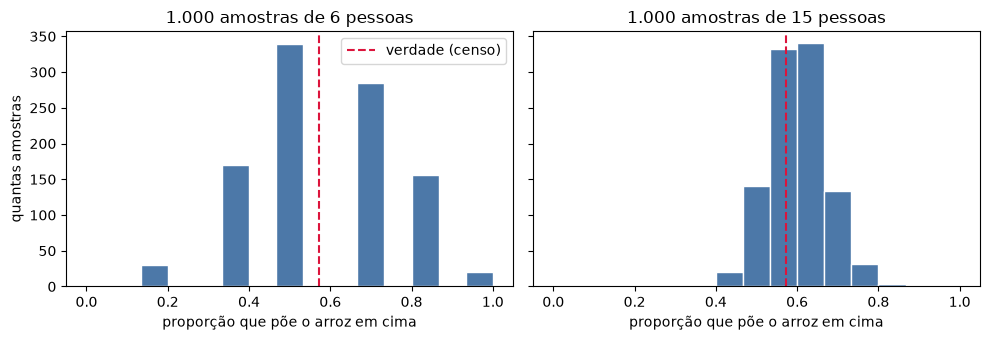

Desvio-padrão das estimativas com n=6:  0.182
Desvio-padrão das estimativas com n=15: 0.071


In [12]:
rng = np.random.default_rng(42)
cima = sala["cima"].to_numpy()

est_6  = [rng.choice(cima, 6,  replace=False).mean() for _ in range(1000)]
est_15 = [rng.choice(cima, 15, replace=False).mean() for _ in range(1000)]

fig, eixos = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True, sharey=True)
for eixo, est, n in zip(eixos, [est_6, est_15], [6, 15]):
    eixo.hist(est, bins=np.linspace(0, 1, 16), color="#4C78A8", edgecolor="white")
    eixo.axvline(censo, color="crimson", linestyle="--", label="verdade (censo)")
    eixo.set_title(f"1.000 amostras de {n} pessoas")
    eixo.set_xlabel("proporção que põe o arroz em cima")
eixos[0].set_ylabel("quantas amostras")
eixos[0].legend()
plt.tight_layout()
plt.show()
print("Desvio-padrão das estimativas com n=6: ", round(float(np.std(est_6)), 3))
print("Desvio-padrão das estimativas com n=15:", round(float(np.std(est_15)), 3))

**O que observar:** as duas montanhas ficam centradas na verdade (a linha tracejada), mas a de 15 pessoas é **bem mais estreita**. Quanto maior a amostra, menos a estimativa balança. Esse "balançar" é o que a **margem de erro** tenta resumir em um número.

Agora vamos para o tamanho das pesquisas reais. Vamos supor que **40% do eleitorado** apoia um candidato (a verdade, que na vida real ninguém conhece) e simular 10.000 pesquisas para cada tamanho de amostra.

In [13]:
verdade = 0.40
tamanhos = [100, 400, 1000, 2000, 5000]

linhas = []
for n in tamanhos:
    resultados = rng.binomial(n, verdade, size=10_000) / n     # 10.000 pesquisas de n pessoas
    linhas.append({
        "n": n,
        "menor resultado": f"{resultados.min():.1%}",
        "maior resultado": f"{resultados.max():.1%}",
        "95% dos resultados ficam entre": f"{np.percentile(resultados, 2.5):.1%} e {np.percentile(resultados, 97.5):.1%}",
    })
print(pd.DataFrame(linhas).to_string(index=False))

   n menor resultado maior resultado 95% dos resultados ficam entre
 100           22.0%           58.0%                  31.0% e 49.0%
 400           30.8%           49.2%                  35.0% e 44.8%
1000           34.8%           46.8%                  37.0% e 43.0%
2000           35.4%           44.8%                  37.9% e 42.2%
5000           37.4%           43.0%                  38.7% e 41.3%


**Ponto de conferência:** com n=1.000, o intervalo onde caem 95% das pesquisas deve ser algo perto de **37% a 43%**. Esse "para mais ou para menos" é exatamente o que as notícias chamam de **margem de erro**.

Repare também que dobrar a amostra **não** corta o erro pela metade. Para reduzir o erro à metade é preciso **quadruplicar** a amostra (a margem cai com a raiz de n). Por isso pesquisas nacionais quase nunca passam de 2.000 a 5.000 pessoas: depois disso, cada entrevista a mais custa caro e melhora pouco.

**E o tamanho da população?** Quase não importa. Uma amostra aleatória de 1.000 pessoas tem praticamente a mesma precisão para uma cidade de 100 mil habitantes ou para o país inteiro. O que pesa é o tamanho da **amostra** e a **qualidade do sorteio**.

## 4. Margem de erro, intervalo de confiança e "95% de confiança"

Três ideias que andam juntas, e que o noticiário costuma embaralhar:

- **Margem de erro:** o "para mais ou para menos" ao redor da estimativa. Se a pesquisa diz 40% com margem de 3 pontos, quer dizer 40% ± 3.
- **Intervalo de confiança:** a faixa que resulta disso. Aqui, de **37% a 43%**.
- **Nível de confiança:** quão "folgada" é a faixa. O padrão é **95%**. A margem de erro só faz sentido **junto** com o nível de confiança: margem de 3 pontos com 95% é outra coisa que margem de 3 pontos com 99%.

A fórmula (só para ver de onde vem, não precisa decorar) é:

`margem = z × √( p × (1 − p) / n )`

onde `p` é a proporção encontrada, `n` é o tamanho da amostra e `z` é **1,96** para 95% de confiança (2,58 para 99%, 1,64 para 90%). O pior caso é `p = 50%`, e aí a conta vira, de cabeça, **margem ≈ 1 / √n**. Com n=1.000: 1/31,6 ≈ 3,1 pontos. Isso explica por que quase toda pesquisa nacional de 2.000 entrevistas diz "margem de 2 pontos".

In [14]:
def margem_erro(p, n, z=1.96):
    return z * np.sqrt(p * (1 - p) / n)

print("Pior caso (p = 50%), confiança de 95%:")
for n in [100, 400, 1000, 2000, 5000, 9700]:
    print(f"  n = {n:>5}  ->  margem de ±{margem_erro(0.5, n):.2%}   (atalho 1/√n = {1 / np.sqrt(n):.1%})")

print()
print("Mesma amostra (n=1.000, p=40%), confiança diferente:")
for nome, z in [("90%", 1.645), ("95%", 1.96), ("99%", 2.576)]:
    print(f"  confiança {nome}: ±{margem_erro(0.40, 1000, z):.1%}")

Pior caso (p = 50%), confiança de 95%:
  n =   100  ->  margem de ±9.80%   (atalho 1/√n = 10.0%)
  n =   400  ->  margem de ±4.90%   (atalho 1/√n = 5.0%)
  n =  1000  ->  margem de ±3.10%   (atalho 1/√n = 3.2%)
  n =  2000  ->  margem de ±2.19%   (atalho 1/√n = 2.2%)
  n =  5000  ->  margem de ±1.39%   (atalho 1/√n = 1.4%)
  n =  9700  ->  margem de ±1.00%   (atalho 1/√n = 1.0%)

Mesma amostra (n=1.000, p=40%), confiança diferente:
  confiança 90%: ±2.5%
  confiança 95%: ±3.0%
  confiança 99%: ±4.0%


**O que observar:** quem quer mais confiança paga com uma faixa **mais larga**. Não existe pesquisa que dá "certeza": existe um trade-off entre precisão (faixa estreita) e confiança (faixa que acerta mais vezes).

### O que quer dizer, de verdade, "95% de confiança"?

Não é "95% de chance de a verdade estar dentro desta faixa específica". O sentido correto é sobre o **método**: se a gente repetisse a pesquisa muitas e muitas vezes, em **95% das repetições** o intervalo calculado pegaria o valor verdadeiro. Em **1 de cada 20**, mesmo com tudo certo, a pesquisa **erra além da margem**. Vamos ver isso acontecer.

Das 10.000 pesquisas, 94.6% tiveram intervalo que pegou a verdade.


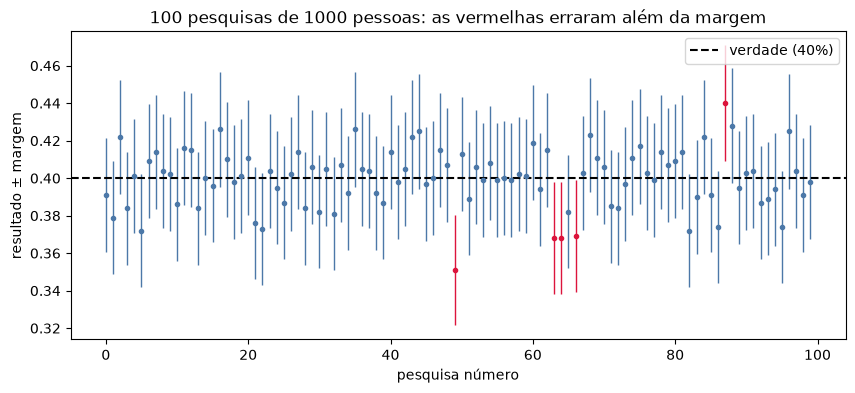

Pesquisas em vermelho nas 100 primeiras: 5


In [15]:
n = 1000
verdade = 0.40
resultados = rng.binomial(n, verdade, size=10_000) / n
margens = margem_erro(resultados, n)
acertou = np.abs(resultados - verdade) <= margens
print(f"Das 10.000 pesquisas, {acertou.mean():.1%} tiveram intervalo que pegou a verdade.")

# desenhando as 100 primeiras pesquisas
fig, eixo = plt.subplots(figsize=(10, 4))
for i in range(100):
    cor = "#4C78A8" if acertou[i] else "crimson"
    eixo.errorbar(i, resultados[i], yerr=margens[i], fmt="o", color=cor, markersize=3, linewidth=1)
eixo.axhline(verdade, color="black", linestyle="--", label="verdade (40%)")
eixo.set_xlabel("pesquisa número")
eixo.set_ylabel("resultado ± margem")
eixo.set_title(f"100 pesquisas de {n} pessoas: as vermelhas erraram além da margem")
eixo.legend()
plt.show()
print("Pesquisas em vermelho nas 100 primeiras:", int((~acertou[:100]).sum()))

**Ponto de conferência:** perto de 95% de acerto no total, e algo como 3 a 7 barras vermelhas nas 100 primeiras. Se der exatamente 5, é coincidência; se der 4 ou 6, está dentro do esperado.

**Três avisos que quase ninguém dá:**

1. **A margem de erro só mede a "sorte do sorteio".** Ela **não** captura viés. Uma enquete com 50 mil respostas pode ter margem de ±0,4 ponto no papel e errar por 8 pontos na realidade. Vamos ver no próximo item.
2. **Subgrupos têm margem maior.** Se a pesquisa tem 2.000 pessoas, mas você olha só as mulheres evangélicas de 16 a 24 anos (digamos, 80 pessoas), a margem desse recorte é de uns ±11 pontos, não de ±2.
3. **A margem de uma diferença é maior que a margem de cada número.** Isso é o que decide o "empate técnico", logo abaixo.

### Empate técnico: a manchete diz que um candidato está na frente. Está?

Uma pesquisa com 1.200 entrevistas encontra o candidato A com **41%** e o candidato B com **38%**. A manchete: *"A lidera por 3 pontos"*. Vamos conferir.

In [16]:
a, b, n = 0.41, 0.38, 1200
print(f"A: {a:.0%} ± {margem_erro(a, n):.1%}  ->  de {a - margem_erro(a, n):.1%} a {a + margem_erro(a, n):.1%}")
print(f"B: {b:.0%} ± {margem_erro(b, n):.1%}  ->  de {b - margem_erro(b, n):.1%} a {b + margem_erro(b, n):.1%}")

# margem da DIFERENÇA entre dois candidatos que saíram da mesma pesquisa
margem_dif = 1.96 * np.sqrt((a + b - (a - b) ** 2) / n)
print()
print(f"Diferença encontrada: {a - b:.1%}")
print(f"Margem de erro da diferença: ±{margem_dif:.1%}")
print(f"A diferença pode estar, de fato, entre {a - b - margem_dif:.1%} e {a - b + margem_dif:.1%}")

A: 41% ± 2.8%  ->  de 38.2% a 43.8%
B: 38% ± 2.7%  ->  de 35.3% a 40.7%

Diferença encontrada: 3.0%
Margem de erro da diferença: ±5.0%
A diferença pode estar, de fato, entre -2.0% e 8.0%


**Como ler:** a diferença de 3 pontos tem margem de uns ±5. A faixa vai de **negativo** (B na frente) a positivo (A na frente). A pesquisa **não consegue dizer** quem lidera. Isso é o "empate técnico" na prática. A regra de bolso do jornalismo é "diferença menor que a margem de erro = empate", e ela até é conservadora, porque a margem da diferença é, na verdade, maior ainda.

Resultado: *"A lidera por 3 pontos"* é uma manchete que a pesquisa **não sustenta**.

### E "o candidato oscilou 2 pontos"?

Suponha que a **verdade não muda** (40% o tempo todo). Mesmo assim, pesquisas sucessivas com n=1.000 vão "oscilar". Vamos simular 12 pesquisas semanais sem nenhuma mudança real na opinião.

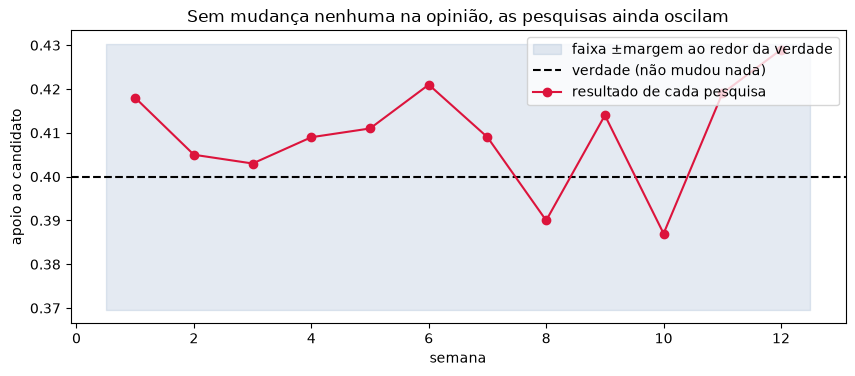

Variação entre a menor e a maior pesquisa: 4.2 pontos


In [17]:
semanas = np.arange(1, 13)
semanais = rng.binomial(1000, 0.40, size=12) / 1000
m = margem_erro(0.40, 1000)

fig, eixo = plt.subplots(figsize=(10, 3.8))
eixo.fill_between([0.5, 12.5], 0.40 - m, 0.40 + m, color="#4C78A8", alpha=0.15, label="faixa ±margem ao redor da verdade")
eixo.axhline(0.40, color="black", linestyle="--", label="verdade (não mudou nada)")
eixo.plot(semanas, semanais, "o-", color="crimson", label="resultado de cada pesquisa")
eixo.set_xlabel("semana")
eixo.set_ylabel("apoio ao candidato")
eixo.set_title("Sem mudança nenhuma na opinião, as pesquisas ainda oscilam")
eixo.legend(loc="upper right")
plt.show()
print("Variação entre a menor e a maior pesquisa:", f"{(semanais.max() - semanais.min()) * 100:.1f} pontos")

**O que observar:** o gráfico anda para cima e para baixo sem que nada tenha mudado. Moral para quem comunica: **oscilação dentro da margem de erro não é notícia**. Só vale como tendência se a mudança for maior que a margem **ou** se várias pesquisas, de institutos diferentes, apontarem na mesma direção.

## 5. Tamanho não cura viés: a enquete com 14 mil respostas contra a pesquisa de 1.000

Agora o caso que mais engana. Imagine um eleitorado fictício de 300 mil pessoas, em três faixas etárias, com apoio diferente ao candidato A em cada uma:

| Faixa | % do eleitorado | Apoio ao candidato A |
|---|---|---|
| 16 a 34 anos | 30% | 55% |
| 35 a 59 anos | 45% | 40% |
| 60 anos ou mais | 25% | 25% |

A **verdade** é uma média ponderada: 0,30×55% + 0,45×40% + 0,25×25% ≈ **40,8%**. Vamos comparar dois jeitos de pesquisar:

- **Pesquisa aleatória**, com 1.000 pessoas sorteadas do eleitorado;
- **Enquete na internet**, aberta a todos, onde quem **mais responde** são os jovens (que passam mais tempo online e seguem o perfil que divulgou a enquete).

In [18]:
N = 300_000
faixas = np.array(["16-34", "35-59", "60+"])
share = np.array([0.30, 0.45, 0.25])
apoio = np.array([0.55, 0.40, 0.25])

idx = rng.choice(3, size=N, p=share)
apoia = rng.random(N) < apoio[idx]
eleitorado = pd.DataFrame({"faixa": faixas[idx], "apoia": apoia})
verdade_pop = eleitorado["apoia"].mean()
print(f"Verdade no eleitorado: {verdade_pop:.1%}")

# 1) pesquisa aleatória de 1.000 pessoas
aleatoria = eleitorado.sample(1000, random_state=2)

# 2) enquete aberta: a chance de responder cai com a idade
prob_responder = pd.Series({"16-34": 0.10, "35-59": 0.03, "60+": 0.01})
respondeu = rng.random(N) < eleitorado["faixa"].map(prob_responder).to_numpy()
enquete = eleitorado[respondeu]

resumo = pd.DataFrame({
    "método": ["Pesquisa aleatória", "Enquete aberta"],
    "respostas": [len(aleatoria), len(enquete)],
    "estimativa": [aleatoria["apoia"].mean(), enquete["apoia"].mean()],
    "margem 'no papel'": [margem_erro(aleatoria["apoia"].mean(), len(aleatoria)),
                          margem_erro(enquete["apoia"].mean(), len(enquete))],
})
resumo["erro real"] = resumo["estimativa"] - verdade_pop
for col in ["estimativa", "margem 'no papel'", "erro real"]:
    resumo[col] = (resumo[col] * 100).round(1)
print(resumo.to_string(index=False))
print()
print("Quem entrou em cada amostra (% por faixa):")
print(pd.DataFrame({
    "eleitorado": eleitorado["faixa"].value_counts(normalize=True),
    "aleatória": aleatoria["faixa"].value_counts(normalize=True),
    "enquete": enquete["faixa"].value_counts(normalize=True),
}).round(3).mul(100).sort_index())

Verdade no eleitorado: 40.7%
            método  respostas  estimativa  margem 'no papel'  erro real
Pesquisa aleatória       1000        42.2                3.1        1.5
    Enquete aberta      13888        49.2                0.8        8.5

Quem entrou em cada amostra (% por faixa):
       eleitorado  aleatória  enquete
faixa                                
16-34        30.1       27.9     65.5
35-59        45.0       48.8     28.9
60+          24.9       23.3      5.6


**O que observar:**

- A enquete tem **13 ou 14 mil respostas**, e uma margem de erro "no papel" minúscula (perto de ±0,8 ponto). Mesmo assim, **erra por cerca de 8 pontos**.
- A pesquisa aleatória de 1.000 pessoas fica a poucos pontos da verdade, dentro da margem.
- A tabela de composição mostra o culpado: a enquete tem **muito mais jovens** do que o eleitorado. Ela não é representativa, e **nenhuma quantidade de respostas conserta isso**.

A frase para guardar: **muita gente respondendo não é o mesmo que a amostra ser boa**. Uma enquete de rede social mede **quem respondeu**, não o eleitorado. A margem de erro da enquete é um número bonito calculado em cima de uma hipótese (sorteio aleatório) que **não foi respeitada**.

## 6. Representatividade na prática: estratificação e ponderação

Pesquisas sérias tentam garantir a composição da amostra de dois jeitos:

1. **Cotas ou estratos (antes):** o instituto define, a partir de dados oficiais (Censo/IBGE, perfil do eleitorado do TSE), quantas pessoas de cada perfil precisa entrevistar (sexo, idade, escolaridade, região...).
2. **Ponderação (depois):** se a amostra saiu com composição diferente da população, cada resposta recebe um **peso** para corrigir. Peso = (% do grupo na população) ÷ (% do grupo na amostra). Quem está sub-representado "pesa mais".

Voltando à sala: vamos supor que uma pesquisa de **10 pessoas** pegou muito mais meninas que meninos. Veja o que a ponderação faz.

In [19]:
pop_prop = sala["grupo"].value_counts(normalize=True)            # composição REAL da sala
print("Composição da sala:", pop_prop.round(2).to_dict())

# amostra torta de propósito: 8 meninas e 2 meninos
amostra = pd.concat([
    sala[sala["grupo"] == "F"].sample(8, random_state=14),
    sala[sala["grupo"] == "M"].sample(2, random_state=14),
])
amostra_prop = amostra["grupo"].value_counts(normalize=True)
print("Composição da amostra:", amostra_prop.round(2).to_dict())

amostra["peso"] = amostra["grupo"].map(pop_prop / amostra_prop)
print("Pesos:", amostra.groupby("grupo")["peso"].first().round(2).to_dict())

sem_peso = amostra["cima"].mean()
com_peso = (amostra["cima"] * amostra["peso"]).sum() / amostra["peso"].sum()
print()
print(f"Verdade da sala (censo):  {censo:.0%}")
print(f"Amostra sem ponderar:     {sem_peso:.0%}")
print(f"Amostra ponderada:        {com_peso:.0%}")

Composição da sala: {'F': 0.71, 'M': 0.29}
Composição da amostra: {'F': 0.8, 'M': 0.2}
Pesos: {'F': 0.89, 'M': 1.43}

Verdade da sala (censo):  57%
Amostra sem ponderar:     80%
Amostra ponderada:        71%


**Ponto de conferência:** os pesos devem ser menores que 1 para as meninas (sobre-representadas) e maiores que 1 para os meninos (sub-representados). A ponderação **corrige a composição**. Como são só 10 pessoas, o acaso ainda pode deixar a estimativa longe da verdade: ponderar não faz milagre, só tira o erro que vem da composição.

**Limites da ponderação (importante para ler pesquisas):**

- Só corrige o que foi **medido e comparado com a população**. Se a amostra tem poucos eleitores de baixa escolaridade e o instituto não pondera por escolaridade, o problema continua.
- Se quem **não responde** pensa diferente de quem responde, **dentro do mesmo grupo**, a ponderação não resolve.
- Pesos muito altos (um grupo minúsculo "falando" por muita gente) deixam a estimativa mais instável, o que **aumenta a margem de erro real**.

No exercício de hoje você vai testar justamente isso com a enquete do item 5.

## 7. Como ler a ficha técnica de uma pesquisa eleitoral

No Brasil, pesquisa eleitoral divulgada precisa ser **registrada no TSE** antes da divulgação (sistema **PesqEle**, `pesqele-divulgacao.tse.jus.br`). Qualquer pessoa pode consultar o registro, e é lá que mora a ficha técnica verdadeira. Veja os campos que você deve checar, com um **exemplo fictício** (os números abaixo não são de nenhum instituto real):

| Campo | O que significa | Exemplo (fictício) |
|---|---|---|
| Número do registro | Prova que a pesquisa foi registrada | BR-00000/2026 |
| Quem contratou e quem pagou | Possível interesse na divulgação | Veículo X |
| Instituto | Quem executou | Instituto Y |
| Período de campo | Datas das entrevistas (a pesquisa é uma **foto do passado**) | 10 a 14/10 |
| Universo | Quem a amostra representa | Eleitores de 16+ anos do país |
| Tamanho da amostra | Número de entrevistas | 2.000 |
| Plano amostral | Como as pessoas foram escolhidas (cotas, estratos, sorteio) | Cotas de sexo, idade, escolaridade, região |
| Método de coleta | Domiciliar, telefone, internet | Face a face, em domicílios |
| Ponderação | Se houve ajuste e por quais variáveis | Por sexo, idade, escolaridade |
| Margem de erro e confiança | Quanto ela pode oscilar, e com que garantia | ±2 pontos, 95% |

Regras de bolso para quem comunica:

1. **Sem registro, sem ficha técnica, sem método: não repita o número.** Enquete de rede social e "pesquisa" de WhatsApp entram aqui.
2. **Mencione sempre a data de campo e a margem de erro**, e não diga "lidera" quando a diferença está dentro da margem.
3. **Pesquisa não é previsão.** É um retrato do período de campo, dos que quiseram responder, feito com um método que erra para cima ou para baixo por acaso e **por viés** (quem recusa responder, indecisos, voto envergonhado).
4. **Compare institutos pelo método, não só pelo número.** Dois institutos podem divergir porque um fez telefone e outro presencial, porque ponderaram por variáveis diferentes ou porque a diferença cabe nas margens.
5. **Desconfie de subgrupos:** a margem de "jovens evangélicos do Nordeste" é bem maior que a margem geral.

**Missão rápida (3 minutos):** abra o PesqEle, procure uma pesquisa registrada para presidente em 2026 e localize cada campo da tabela. Qual dos campos estava mais difícil de achar?

## 8. Checklist de bolso: antes de repetir um número de pesquisa

- [ ] Quem foi ouvido e como foram escolhidos? (sorteio, cotas ou "quem quis responder"?)
- [ ] Qual o **tamanho** da amostra e a **margem de erro com o nível de confiança**?
- [ ] Qual foi o **período de campo**? Aconteceu alguma coisa importante depois?
- [ ] A diferença entre candidatos é **maior** que a margem de erro da diferença?
- [ ] A amostra se parece com a população (idade, sexo, escolaridade, região)? Houve ponderação?
- [ ] Existe **registro** no TSE e a ficha técnica está completa?
- [ ] A manchete diz **menos** do que o número permite, no mesmo tom que ele? (nada de "disparou" para uma oscilação de 2 pontos)

## 9. Exercício

Abra `exercicios/exercicio-24-amostragem.ipynb`. Nele, cada pessoa gera o **seu próprio eleitorado fictício** (a partir de uma semente), faz pesquisas aleatórias, compara com uma enquete enviesada, tenta corrigir com ponderação e, no final, avalia uma ficha técnica real do PesqEle.

## Quando der errado

- **Os números da sua rodada não batem com os comentados no texto:** tudo bem, é simulação. O que deve se repetir é o **padrão** (a enquete erra mais que a aleatória; a margem de erro acerta cerca de 95% das vezes).
- **`ModuleNotFoundError`:** rode `!pip install numpy pandas matplotlib` numa célula do Colab, ou, local, `uv pip install -r requirements.txt`.
- **`ValueError` ao trocar `grupo_por_fileira` e `voto_por_fileira`:** as duas listas precisam ter o **mesmo número de fileiras**, e em cada fileira o número de letras de grupo e de voto precisa bater.
- **PesqEle fora do ar ou sem pesquisa que você procura:** registre isso e escolha outra pesquisa registrada; não substitua por notícia sem ficha técnica.